# ADME_ML — results

Reads the per-endpoint metrics pickles and plots them. Nothing is refitted here, so the notebook is cheap to re-run.

- **RF dir** `params.METRICS_PKL_RF_DIR` — 6 arms per endpoint
- **chemprop dir** `params.METRICS_PKL_CP_DIR` — 3 arms per endpoint

Both figures take `metric=` (`r2` squared Pearson, or `r2det` the calibration-sensitive selection metric) and `dpi=` (the save switch: `None` writes no file).

In [1]:
%load_ext autoreload
%autoreload 2

## repo root on sys.path, so `python.` imports whether the kernel starts in vignettes/ or in the root
import os, sys
sys.path[:0] = [os.path.abspath('..'), os.path.abspath('.')]

## imports — pyplot for show(), the config reader, and the two figure helpers
import matplotlib.pyplot as plt
from python.ADME_build_ML import PARAMS       # importing it also chdirs to the repo root
import python.functions as fn

## params — every YAML key becomes an attribute (METRICS_PKL_*, ADME_ENDPOINTS, webapp, SERAC_C)
params = PARAMS('config/config.yaml').load_params()

> loaded 20 params from config/config.yaml


## 1. 2026-09-09

> saved output/figures/bar_summary_RF_CP_r2.png (dpi=150)
winner per arm, r2 (no internal compound in any transfer training set)
              n  ext_->_internal ext_->_internal_by  internal_cv internal_cv_by  augmented_cv augmented_cv_by           note
solubility  120            0.577                 RF        0.680             RF         0.757        chemprop           all8
logd        317            0.620                 RF        0.818             RF         0.840        chemprop       sol_lipo
mdck        107            0.402                 RF        0.483             RF         0.542      near-shell  dist060_agree
mdck_inh    146            0.585                 RF        0.684             RF         0.695              RF     all public
hlm         324            0.329           chemprop        0.595             RF         0.616        chemprop      clearance
mlm         324            0.457           chemprop        0.666             RF         0.664        chemprop      cleara

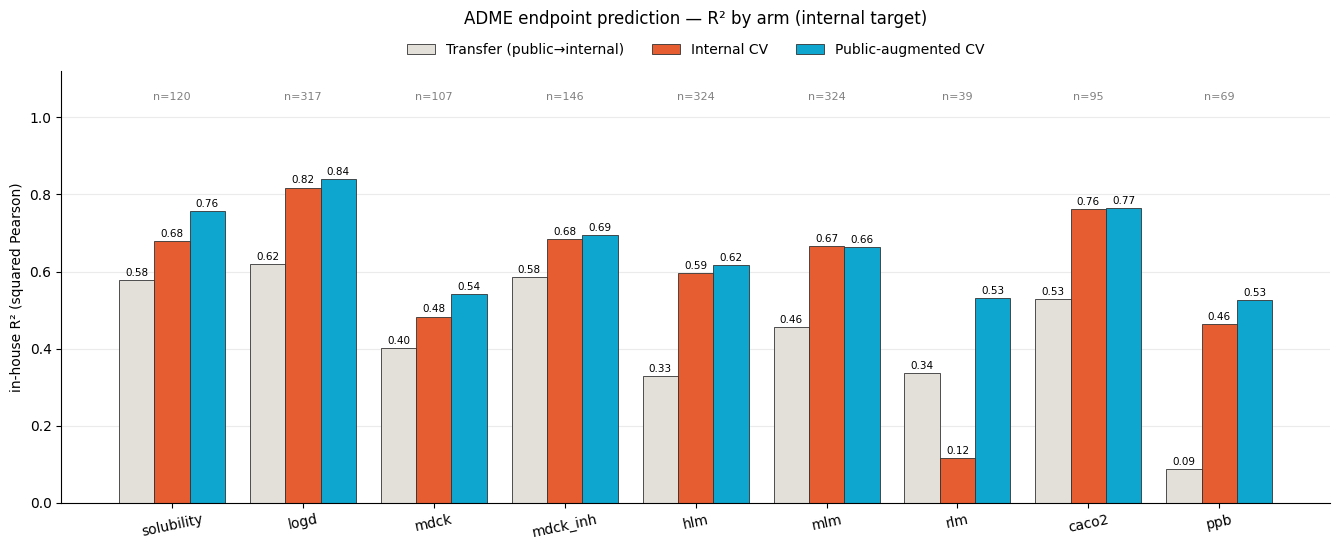

In [7]:
## RF only — transfer (public->internal) / internal CV / public-augmented CV, per endpoint
# dpi is the SAVE SWITCH: None shows the figure and writes no file; set e.g. dpi=150 to export a png
D = '20260909'
# fig, rf_df = fn.plot_bar_summary_RF_all_endpoints('output/results/'+D+'_metrics_rf', params, metric='r2', out_png=None, dpi=150);plt.show()
fig, best_df = fn.plot_bar_summary_RF_CP_all_endpoints('output/results/'+D+'_metrics_rf', 'output/results/'+D+'_metrics_cp', params, metric='r2',out_png=None, dpi=150);plt.show()

## 2026-09-23

> saved output/figures/bar_summary_RF_CP_r2.png (dpi=150)
winner per arm, r2 (no internal compound in any transfer training set)
              n  ext_->_internal ext_->_internal_by  internal_cv internal_cv_by  augmented_cv augmented_cv_by              note
solubility  162            0.548                 RF        0.701             RF         0.707        chemprop              all8
logd        359            0.605                 RF        0.802             RF         0.824      near-shell     dist060_agree
mdck        148            0.358                 RF        0.373       chemprop         0.542      near-shell     dist060_agree
mdck_inh    152            0.584                 RF        0.666             RF         0.693        chemprop  permeability_inh
hlm         364            0.296           chemprop        0.601             RF         0.635        chemprop         clearance
mlm         364            0.444           chemprop        0.682             RF         0.671        ch

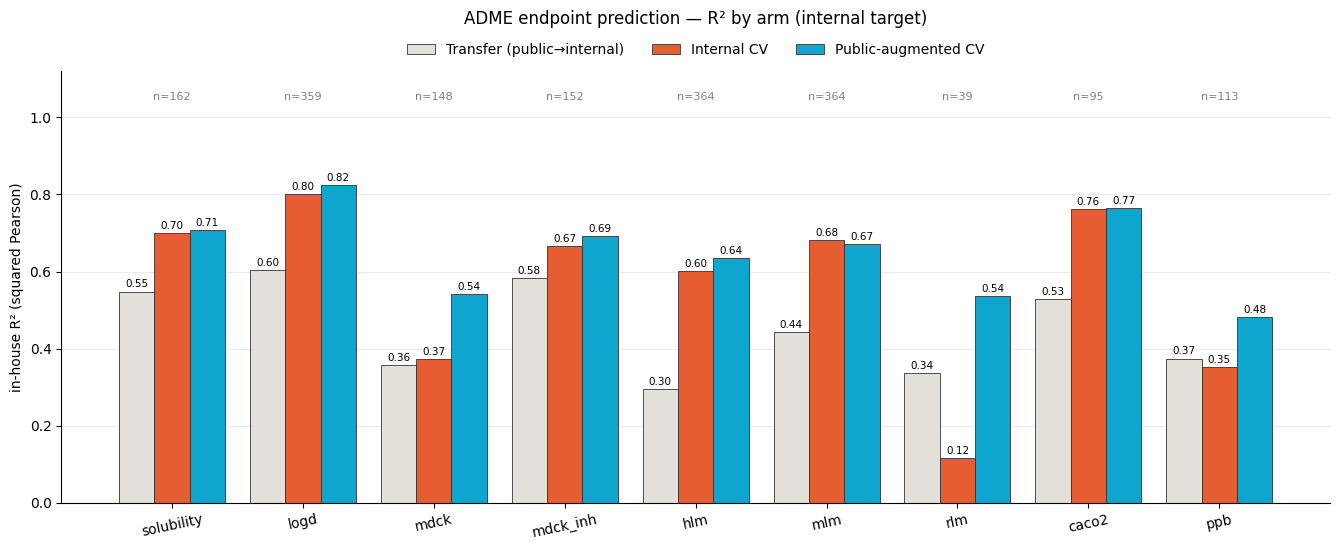

In [8]:
D = '20260923'
# fig, rf_df = fn.plot_bar_summary_RF_all_endpoints('output/results/'+D+'_metrics_rf', params, metric='r2', out_png=None, dpi=150);plt.show()
fig, best_df = fn.plot_bar_summary_RF_CP_all_endpoints('output/results/'+D+'_metrics_rf', 'output/results/'+D+'_metrics_cp', params, metric='r2',out_png=None, dpi=150);plt.show()

## 2026-10-19